# LexiScope — Language Representation, Decoding & Transfer

An executed walkthrough of actual benchmark evidence. Training commands live in the reusable package; this notebook explores committed artifacts offline. The goal is to assess representation choices, decoding behavior and the strength of transfer-learning evidence.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports").exists():
    root = root.parent
report = root / "reports"


def table(name):
    display(pd.read_csv(report / name))


def figure(name):
    display(Image(filename=str(report / "figures" / name)))

## Static semantic geometry

Nearest-neighbor and analogy queries use the full 400k vocabulary. A selected 50-term projection is descriptive; its measured neighbor retention is 71.6–74.8% across seeds. Analogy successes and separated clusters cannot establish general semantic accuracy.

In [2]:
table("static_neighbors.csv")

,query,rank,word,cosine
0,computer,1,computers,0.835772
1,computer,2,software,0.782846
2,computer,3,technology,0.690766
3,computer,4,pc,0.664798
4,computer,5,systems,0.658432
5,ocean,1,sea,0.727745
6,ocean,2,waters,0.724155
7,ocean,3,coast,0.697292
8,ocean,4,atlantic,0.691838
9,ocean,5,seas,0.681202


In [3]:
table("projection_stability.csv")

,seed,original_category_neighbor_purity,projection_category_neighbor_purity,neighbor_retention
0,42,0.88,0.880,0.716
1,43,0.88,0.904,0.728
2,44,0.88,0.888,0.748


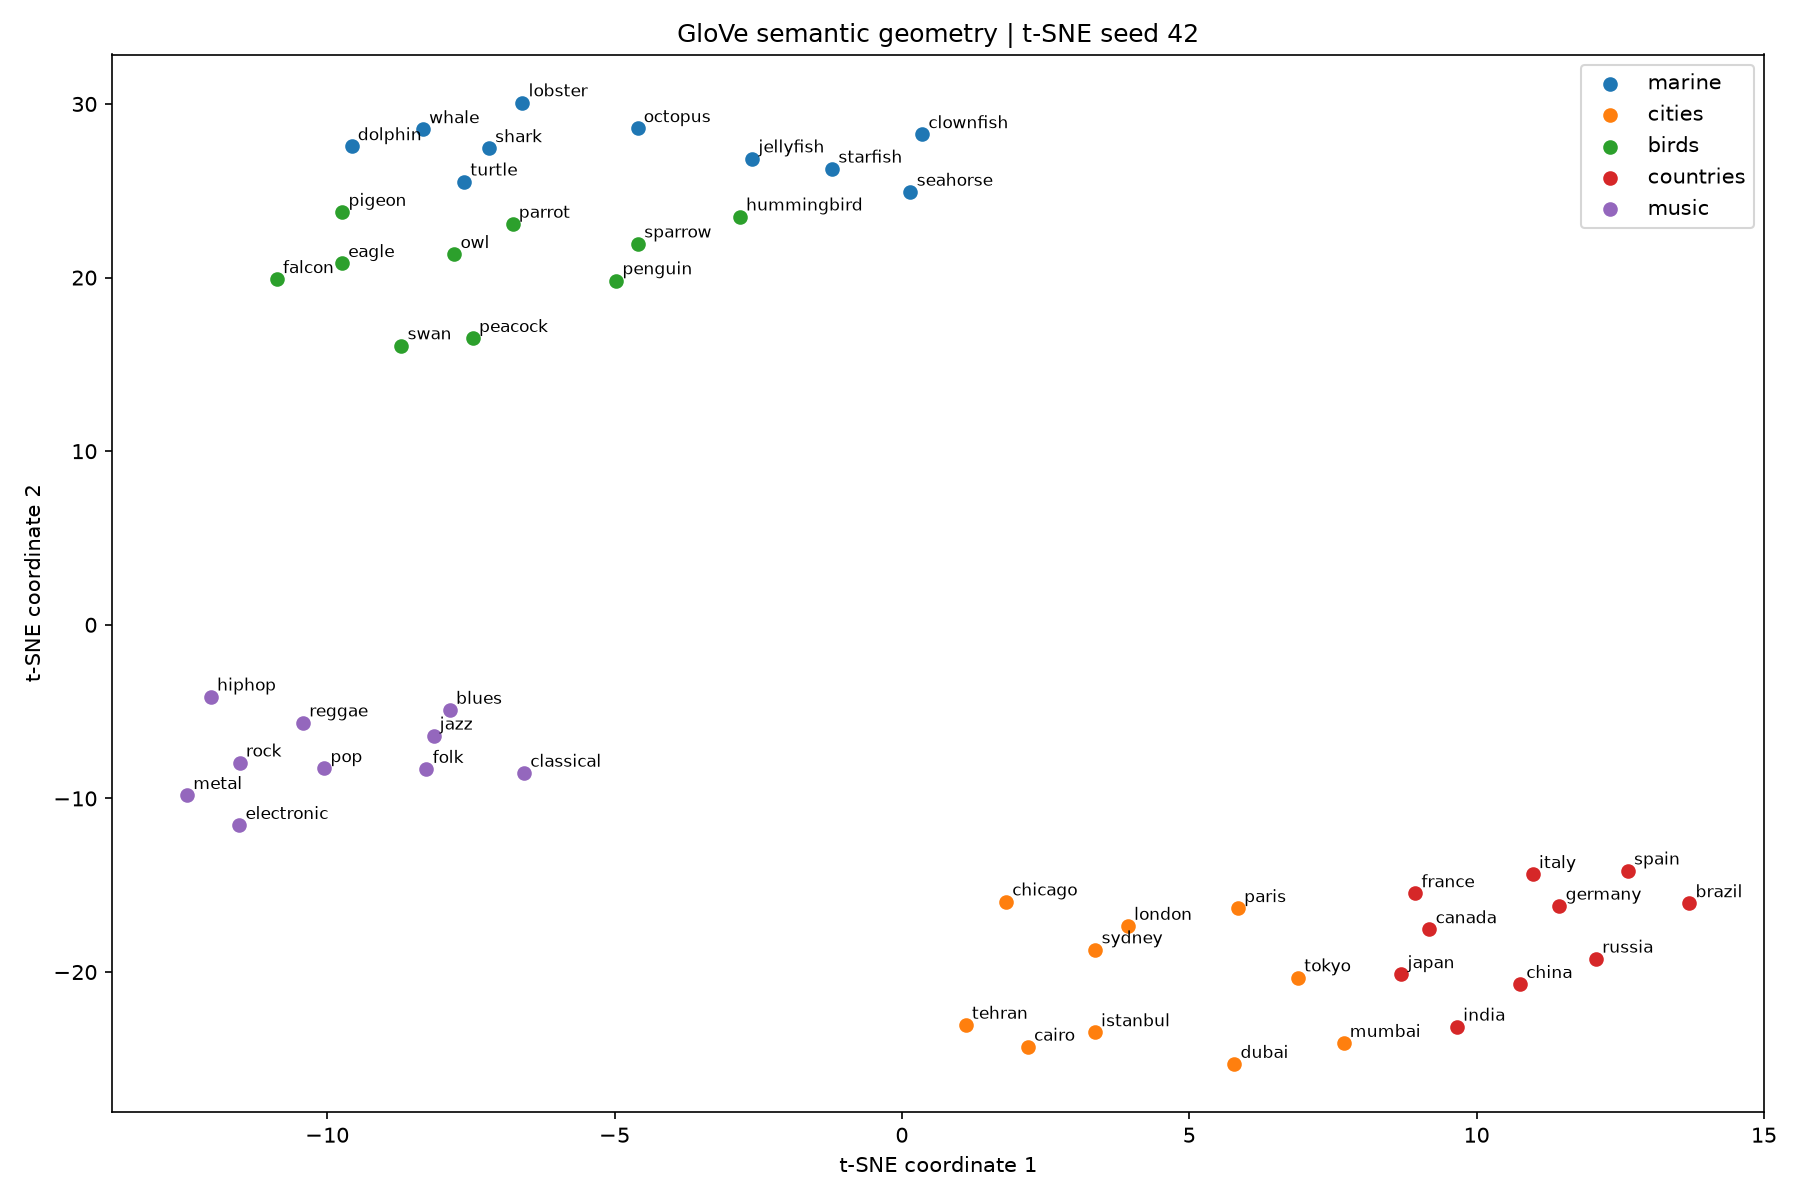

In [4]:
figure("static_semantic_map.png")

## Context and positional controls

Input-layer BERT states include position and segment embeddings and normalization. Matched-position controls have input cosine 1.000 but final cosine 0.696 for bat and 0.526 for charge. Two pairs show context sensitivity; they are not a word-sense benchmark. WordPiece spans are pooled using character-offset alignment.

In [5]:
table("contextual_similarity.csv")

,word,control,layer,cosine,first_positions,second_positions
0,bat,original_positions,0,0.957522,[2],[4]
1,bat,original_positions,1,0.833730,[2],[4]
2,bat,original_positions,2,0.790840,[2],[4]
3,bat,original_positions,3,0.752565,[2],[4]
4,bat,original_positions,4,0.681203,[2],[4]
5,bat,original_positions,5,0.668320,[2],[4]
6,bat,original_positions,6,0.669358,[2],[4]
7,bat,original_positions,7,0.656166,[2],[4]
8,bat,original_positions,8,0.639816,[2],[4]
9,bat,original_positions,9,0.619490,[2],[4]


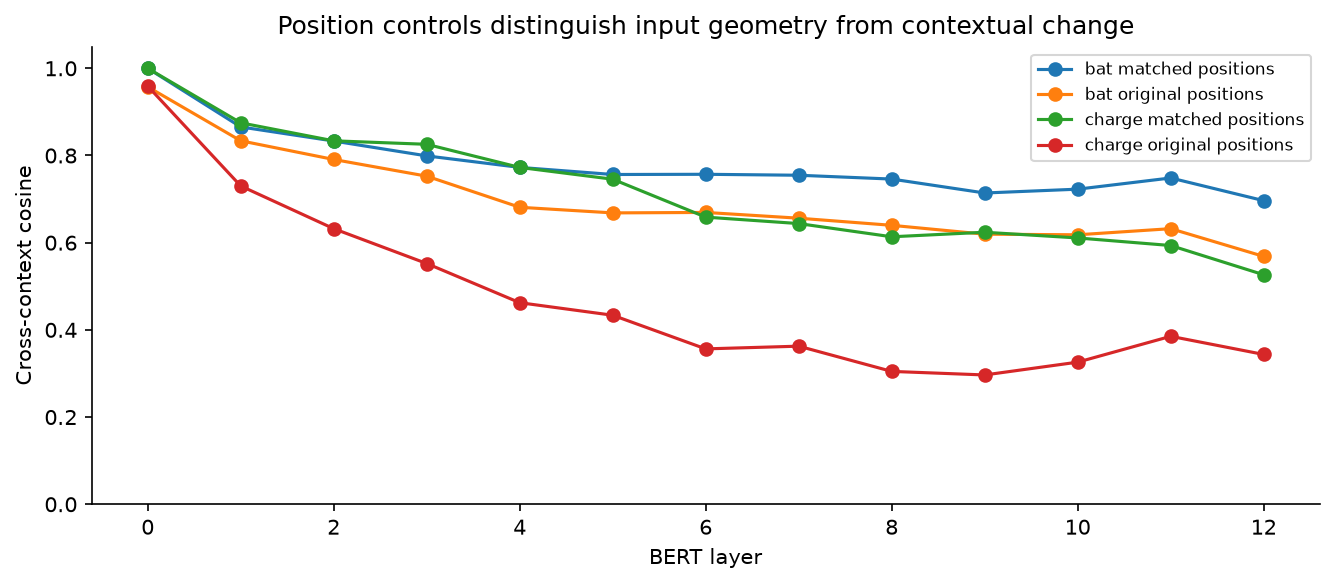

In [6]:
figure("contextual_controls.png")

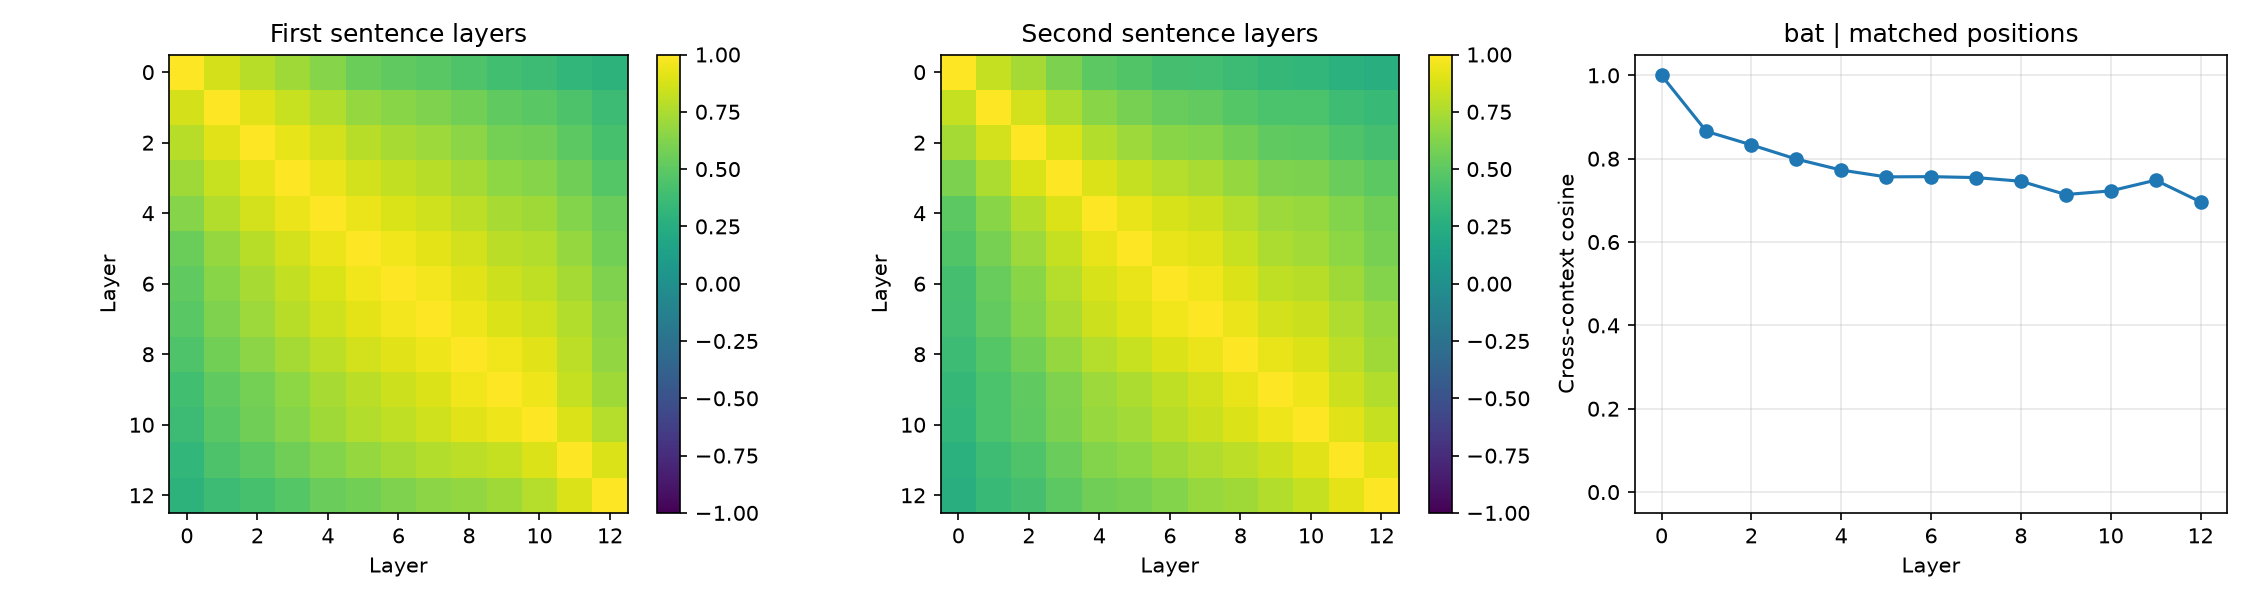

In [7]:
figure("bat_matched_positions.png")

## Controlled decoding

Custom greedy outputs match Hugging Face token IDs for all three prompts, under the same token budget and EOS setting. Seeded stochastic and five-beam samples are retained. Prompt entropy describes distribution concentration, not factuality or calibrated uncertainty.

In [8]:
table("prompt_uncertainty.csv")

,domain,entropy_nats,top_token_probability,top_token
0,story,1.233619,0.659871,girl
1,technical,5.275361,0.058800,so
2,science_fiction,4.945375,0.094747,saw


In [9]:
table("greedy_parity.csv")

,domain,equal_token_ids,new_tokens
0,story,True,25
1,technical,True,9
2,science_fiction,True,25


In [10]:
samples = json.loads((report / "decoding_samples.json").read_text())
display(pd.DataFrame(samples)[["domain", "strategy", "seed", "continuation"]])

,domain,strategy,seed,continuation
0,story,greedy,42,girl named Lily. She loved to play outside in...
1,story,beam,42,girl named Lily. She loved to play in the par...
2,story,sample,42,boy named Timmy. Timmy loved to play outside ...
3,story,sample,43,"girl named Lily. She loved to eat spicy food,..."
4,story,sample,44,girl named Lily. She loved to play with her t...
5,story,custom_temperature,42,boy named Timmy. Timmy loved to jog on his jo...
6,story,custom_top_k,42,"boy named Timmy. Timmy loved to play outside,..."
7,technical,greedy,42,so special to the most more.\n
8,technical,beam,42,"different.\n\nOne day, Lily and her mom went ..."
9,technical,sample,42,more fun.\n


## Language-model learning and size

Both models use shared GPT-2 tokenization and width 64 with two layers. Non-overlapping blocks come from separated book regions. Test perplexity remains high; actual generations remain repetitive. This small-corpus experiment does not establish fluent language competence.

In [11]:
table("language_model_metrics.csv")

,id,test_nll,test_perplexity,best_epoch,validation_loss,training_seconds
0,lstm_lm,7.689759,2185.848034,3,7.307403,13.038977
1,transformer_lm,7.627247,2053.388335,4,7.217681,13.618490


In [12]:
table("parameter_summary.csv")

,id,embedding_and_head,position_parameters,core_parameters,total,embedding_head_fraction
0,lstm_lm,6483153,0,66560,6549713,0.989838
1,transformer_lm,6483153,16384,99968,6599505,0.982370
2,lstm_scratch,3216578,0,66560,3283138,0.979727
3,transformer_scratch,3216578,16384,99968,3332930,0.965090


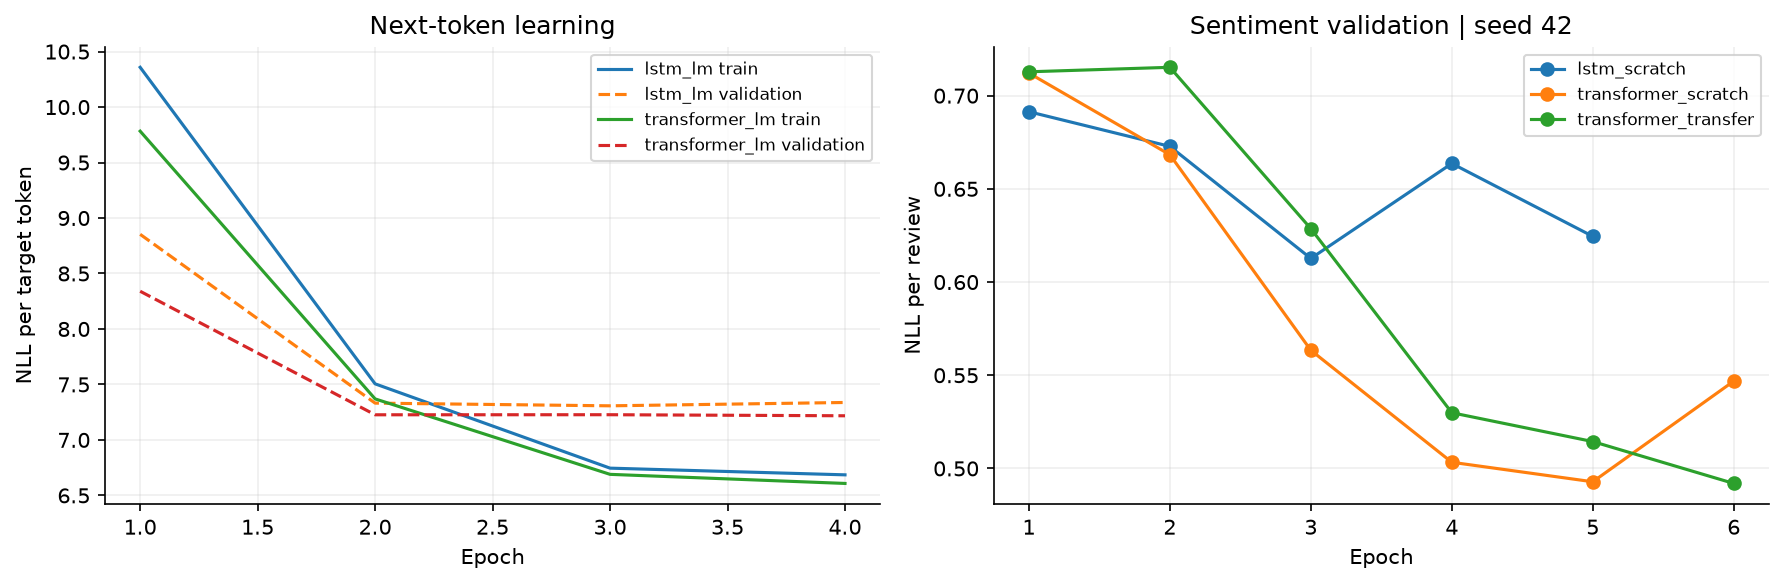

In [13]:
figure("learning_curves.png")

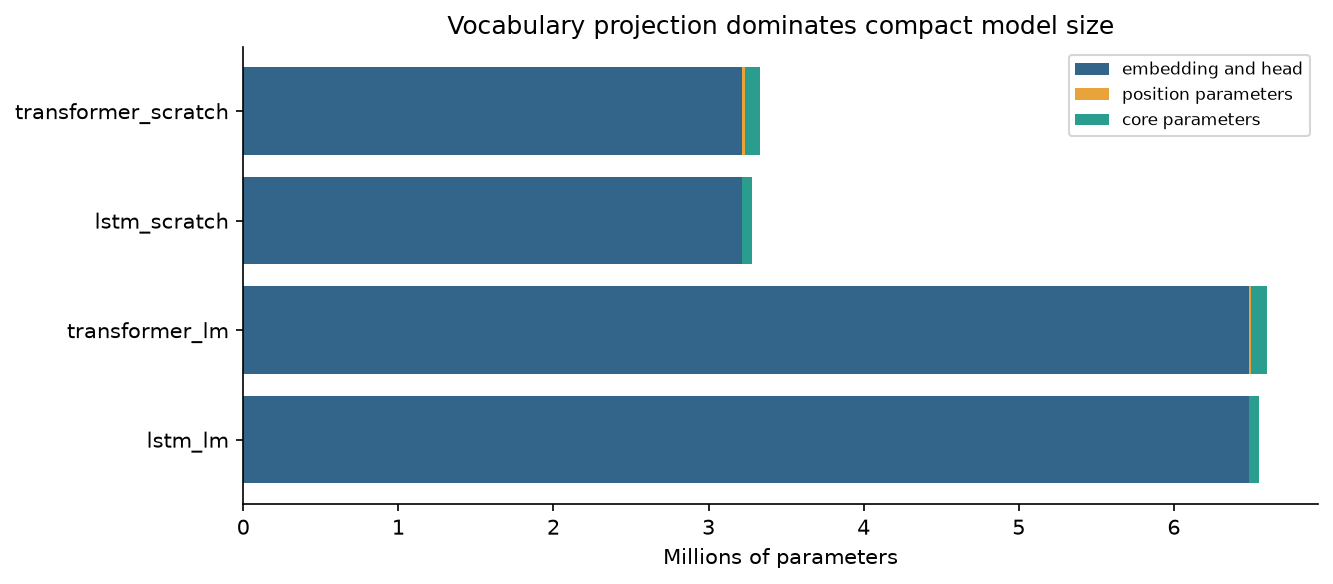

In [14]:
figure("parameter_anatomy.png")

In [15]:
display(json.loads((report / "custom_generations.json").read_text()))

[{'id': 'lstm_lm',
  'prompt': 'The old man',
  'initial': 'The old manrend operators inappropriate GEN peripheradoes pursuantGroupbreak Line Line grasp aisle McGill Hampshire',
  'trained': 'The old man The which the a, the in, the, to, to the Watt'},
 {'id': 'transformer_lm',
  'prompt': 'The old man',
  'initial': 'The old man RooseveltCow Brooks temperfixed commissionediielligence pitches conferred Israelis xml ALEC bogusartisan',
  'trained': 'The old man, and the work, the in, the, to, to the Watt'}]

## Transfer and practical model choice

Three paired downstream seeds share one fixed pretrained body. Mean test accuracy improves from 77.4% to 78.7%, but two bootstrap intervals include zero. TF–IDF wins the validation selection and reaches 89.8% test accuracy. Full-text TF–IDF versus 128-token neural input is a practical pipeline comparison, not an isolated architecture contrast.

In [16]:
table("sentiment_metrics.csv")

,id,seed,accuracy,macro_f1,roc_auc,log_loss,best_epoch,validation_loss,training_seconds
0,lstm_scratch,42,0.683578,0.681735,0.732451,0.627230,3,0.612673,28.980789
1,transformer_scratch,42,0.771696,0.771498,0.850769,0.495777,5,0.492845,47.722102
2,transformer_transfer,42,0.778371,0.777568,0.864107,0.480830,6,0.491952,47.732074
3,transformer_scratch,43,0.782377,0.782093,0.868875,0.509885,6,0.533456,49.644976
4,transformer_transfer,43,0.785047,0.785037,0.862818,0.490898,6,0.494661,48.107121
5,transformer_scratch,44,0.767690,0.764941,0.854608,0.513711,5,0.531163,48.954458
6,transformer_transfer,44,0.798398,0.798317,0.869284,0.479811,6,0.503078,48.275474
7,tfidf_reference,42,0.897864,0.897862,0.959715,0.326025,0,0.327770,1.897614


In [17]:
table("paired_transfer.csv")

,seed,accuracy_delta,bootstrap_low,bootstrap_high,bootstrap_repeats
0,42,0.006676,-0.010013,0.023364,2000
1,43,0.002670,-0.019359,0.026035,2000
2,44,0.030708,0.007343,0.054072,2000


In [18]:
table("validation_candidates.csv")

,id,validation_log_loss
0,lstm_scratch,0.612673
1,transformer_scratch,0.492844
2,transformer_transfer,0.491952
3,tfidf_reference,0.327770


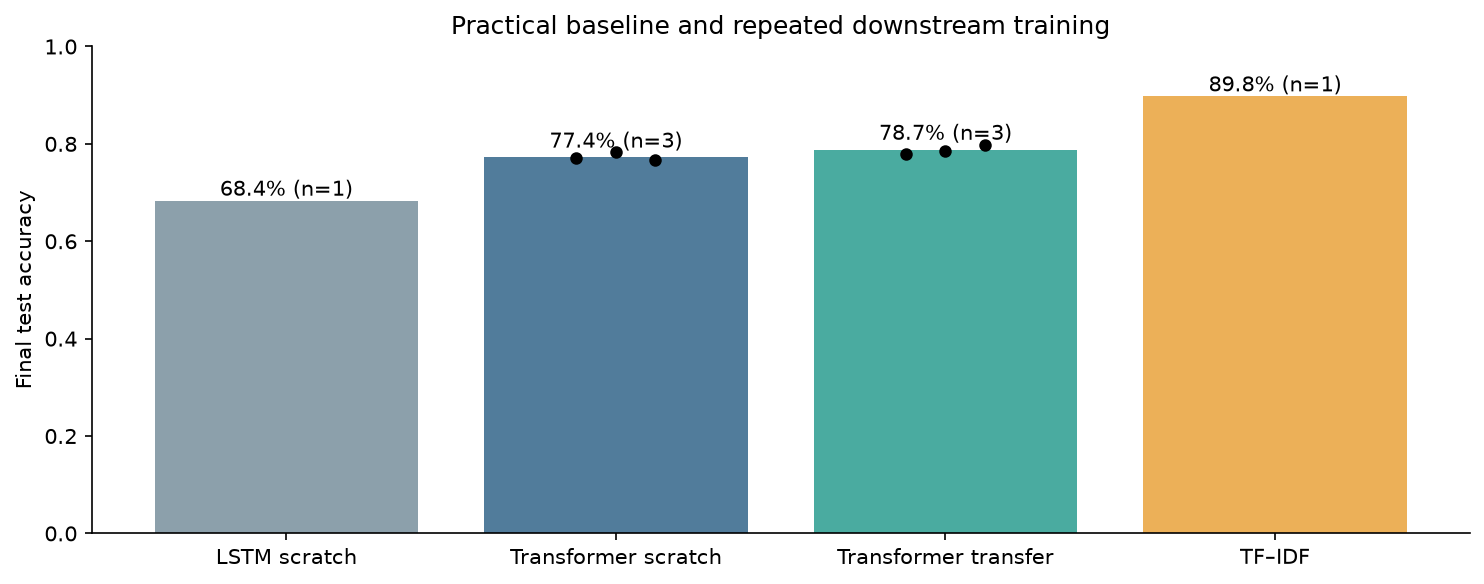

In [19]:
figure("sentiment_comparison.png")

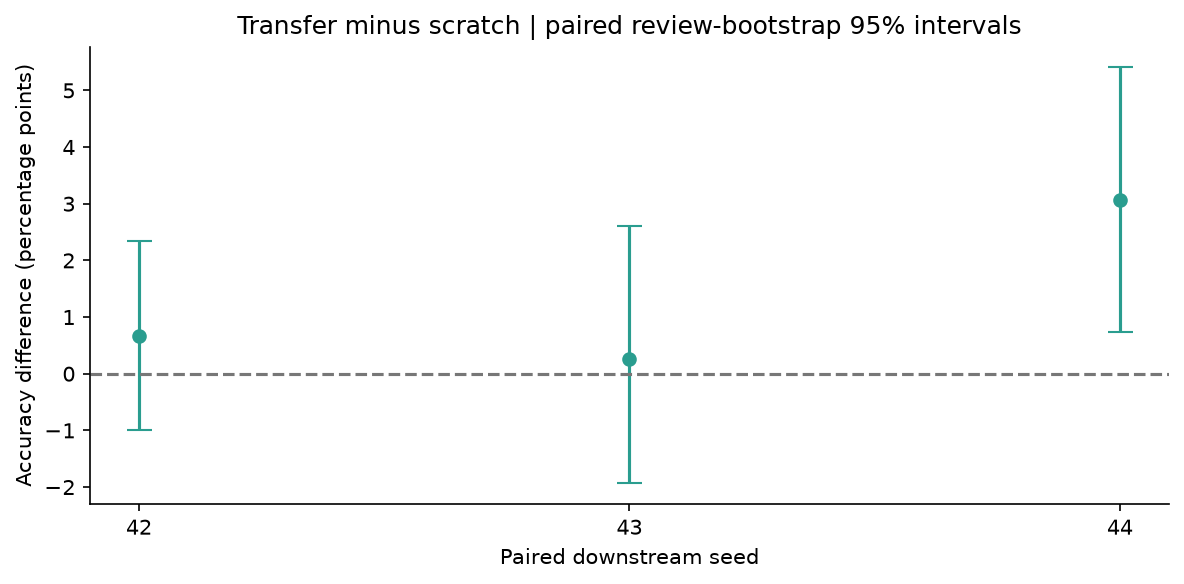

In [20]:
figure("paired_transfer.png")

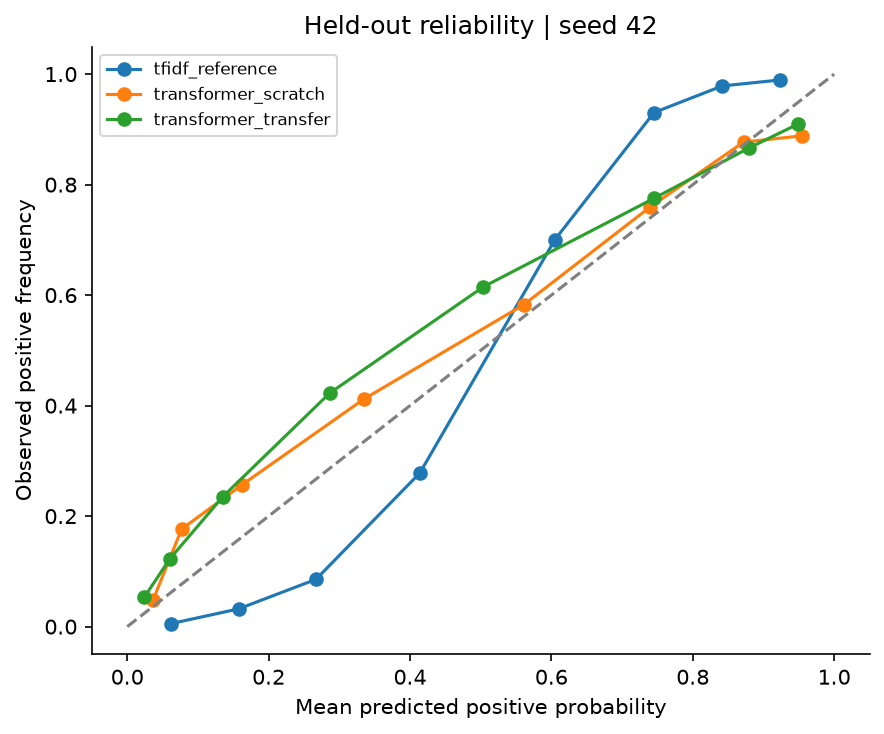

In [21]:
figure("probability_reliability.png")

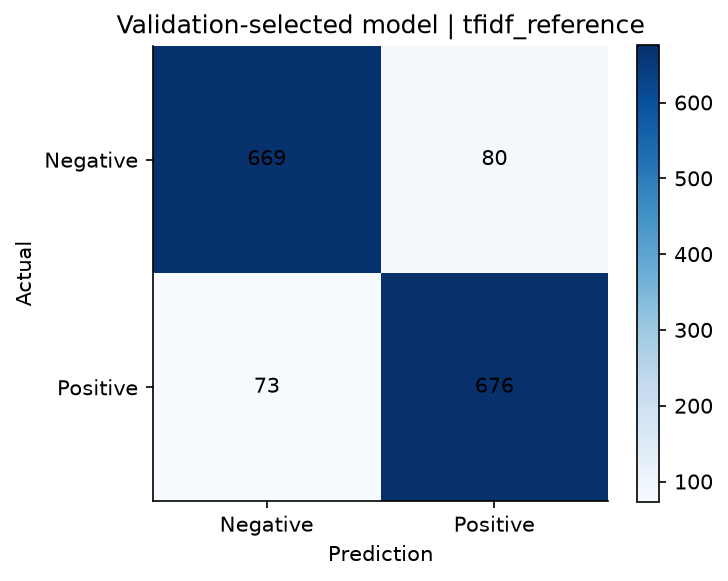

In [22]:
figure("selected_model_confusion.png")

## Provenance and verification

All 10,000 original sentiment texts and labels were matched to the official archive. Seventeen duplicate normalized records were removed before partitioning. The independent auditor checks source labels, metrics, paired intervals, parameter counts, token separation, layer vectors and source hashes. See the repository design and engineering review for limitations and reproduction commands.

In [23]:
display(json.loads((report / "source_audit.json").read_text()))
display(json.loads((report / "run_metadata.json").read_text()))

{'source_rows': 10000,
 'matched_original_imdb_text_and_label': 10000,
 'unmatched_rows': [],
 'note': 'Repeated source texts can match both official partitions; matched archive membership does not establish which original split the local file was sampled from.',
 'chosen_archive_members_by_partition': {'train': 10000},
 'input_sha256': 'c27b5669913c270e125bf2785147e24843c300810821597f553affb035028aff',
 'official_archive_sha256': 'c40f74a18d3b61f90feba1e17730e0d38e8b97c05fde7008942e91923d1658fe'}

{'config': {'width': 64, 'layers': 2, 'dropout': 0.2, 'max_length': 256},
 'lm_epochs_max': 4,
 'classification_epochs_max': 6,
 'patience': 2,
 'lm_batch_size': 16,
 'sentiment_batch_size': 32,
 'lm_sequence_length': 64,
 'sentiment_sequence_length': 128,
 'downstream_seeds': [42, 43, 44],
 'pretraining_seed': 42,
 'pretraining_scope': 'Single shared pretrained checkpoint; seed contrasts are conditional on it',
 'vocabulary_size': 50257,
 'classification_threshold': 0.5,
 'source_hashes': {'generation.py': 'e4d9b8edbc8bf96b786ce9a424ab22517e87e55a9705bacb2489f3890152800a',
  'models.py': 'a06751e61f6e81e9c015bedd4937ea2e403581e7cb1a0bd31035ec3c884010b4',
  'evaluation.py': 'e5c3709ee2186342447085637e88832a81b49ad36df291cf14707fa87a6d1554',
  '__init__.py': '9ac3d4aafed3cfd1a1432d5c60bbeb4c3b334b08d952018af2aeea435eba5b35',
  'visualization.py': 'ad9d7b8f9876c515a5ca12fcc1fb31bc45583cbbee623fe88f754dbe351a2292',
  'decoding.py': '429a8eba9a4974f5373b90751004422de5bc6e3d2764b71a572079ed